In [1]:
from google.colab import drive
import os

# Force a fresh connection to Google Drive
drive.mount('/content/drive', force_remount=True)

# Create and enter your project directory
project_dir = '/content/drive/MyDrive/Bioinformatics_Projects/01_ChrR_Phylogeny'
os.makedirs(project_dir, exist_ok=True)
os.chdir(project_dir)

print("Active project folder:", os.getcwd())

Mounted at /content/drive
Active project folder: /content/drive/MyDrive/Bioinformatics_Projects/01_ChrR_Phylogeny


In [2]:
# 1. Install Biopython to talk to NCBI databases & handle FASTA files
!pip install -q biopython

# 2. Install MAFFT (Multiple Sequence Alignment) and IQ-TREE (Maximum Likelihood Trees)
!apt-get update -qq && apt-get install -y -qq mafft iqtree

# 3. Verify all three tools are installed and ready
!python3 -c "import Bio; print('Biopython version:', Bio.__version__)"
!mafft --version
!iqtree --version

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Extracting templates from packages: 100%
Selecting previously unselected package fonts-lato.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../00-fonts-lato_2.015-1_all.deb ...
Unpacking fonts-lato (2.015-1) ...
Selecting previously unselected package iqtree.
Preparing to unpack .../01-iqtree_2.0.7+dfsg-1build2_amd64.deb ...
Unpacking iqtree (2.0.7+dfsg-1build2) ...
Selecting previously unselected package libclone-perl:amd64.
Preparing to unpack .../02-libclone-perl_0.46-1build3_amd64.deb ...
Unpacking libclone-perl:amd64 (0.46-1build3) ...
Selecting previously unselected package libdata-dump-perl.
Preparing to unpack .../03-libdata-dump-perl_1.25-1_all.deb ...
Unpacking libdata-dump-perl (1.25-1) ...
Selecting previously unselected package libencode-loc

In [3]:
import re
from Bio import Entrez, SeqIO

# 1. Confirm IQ-TREE v2 is ready
!iqtree2 --version

# 2. Configure NCBI Entrez search
Entrez.email = "bioinformatics.student@gmail.com"

# Search NCBI RefSeq for full-length bacterial Chromate Reductase (ChrR) proteins (175-225 amino acids)
query = '("chromate reductase"[Protein Name] OR "ChrR"[Gene Name]) AND Bacteria[Organism] AND srcdb_refseq[PROP] AND 175:225[Sequence Length]'
search_handle = Entrez.esearch(db="protein", term=query, retmax=200)
search_results = Entrez.read(search_handle)
search_handle.close()

id_list = search_results["IdList"]
print(f"\nFound {len(id_list)} candidate sequences on NCBI. Downloading and curating...")

# 3. Download sequences and keep 1 clean representative per bacterial species (up to 30 species)
fetch_handle = Entrez.efetch(db="protein", id=id_list, rettype="fasta", retmode="text")
raw_records = list(SeqIO.parse(fetch_handle, "fasta"))
fetch_handle.close()

curated_records = []
seen_species = set()

for rec in raw_records:
    if "[" not in rec.description or "]" not in rec.description:
        continue
    organism = rec.description.split("[")[-1].rstrip("]")
    parts = organism.split()

    # Keep only valid two-word Genus + species names (skip vague labels like "uncultured bacterium")
    if len(parts) < 2 or parts[0].lower() in ["uncultured", "unclassified", "candidatus", "bacterium"]:
        continue
    if parts[1].lower() in ["sp.", "bacterium", "strain", "endosymbiont"]:
        continue

    species_clean = re.sub(r'[^A-Za-z0-9]', '', parts[0]) + "_" + re.sub(r'[^A-Za-z0-9]', '', parts[1])

    if species_clean not in seen_species:
        seen_species.add(species_clean)
        accession = rec.id.split(".")[0]
        rec.id = f"{species_clean}_{accession}"
        rec.description = ""
        curated_records.append(rec)

    if len(curated_records) >= 30:
        break

# 4. Add 1 homologous outgroup (FMN-dependent NADH-azoreductase AzoR from E. coli) to root the tree
out_search = Entrez.esearch(db="protein", term='"FMN-dependent NADH-azoreductase"[Protein Name] AND "Escherichia coli"[Organism] AND srcdb_refseq[PROP] AND 190:215[Sequence Length]', retmax=1)
out_id = Entrez.read(out_search)["IdList"]
out_search.close()

out_fetch = Entrez.efetch(db="protein", id=out_id, rettype="fasta", retmode="text")
out_rec = next(SeqIO.parse(out_fetch, "fasta"))
out_fetch.close()
out_rec.id = f"OUTGROUP_Ecoli_AzoR_{out_rec.id.split('.')[0]}"
out_rec.description = ""
curated_records.append(out_rec)

# 5. Save the curated FASTA file to Google Drive
output_file = "chrr_curated.fasta"
SeqIO.write(curated_records, output_file, "fasta")

print(f"Saved {len(curated_records)} curated sequences (30 bacterial species + 1 outgroup) to '{output_file}':\n")
for r in curated_records:
    print(f"  - {r.id} ({len(r.seq)} aa)")

IQ-TREE multicore version 2.0.7 for Linux 64-bit built Apr  1 2024
Developed by Bui Quang Minh, Nguyen Lam Tung, Olga Chernomor,
Heiko Schmidt, Dominik Schrempf, Michael Woodhams.


Found 200 candidate sequences on NCBI. Downloading and curating...
Saved 15 curated sequences (30 bacterial species + 1 outgroup) to 'chrr_curated.fasta':

  - Brevundimonas_bullata_WP_524806893 (217 aa)
  - Escherichia_coli_WP_523605168 (188 aa)
  - Caulobacter_segnis_WP_515904844 (212 aa)
  - Brevundimonas_vesicularis_WP_515160986 (212 aa)
  - Shigella_boydii_WP_073804532 (188 aa)
  - Brevundimonas_albigilva_WP_505859588 (213 aa)
  - Escherichia_albertii_WP_497721333 (188 aa)
  - Cereibacter_sphaeroides_WP_009563144 (213 aa)
  - Brevundimonas_sediminis_WP_420469569 (212 aa)
  - Brevundimonas_huaxiensis_WP_483735501 (212 aa)
  - Shigella_flexneri_WP_144130352 (188 aa)
  - Brevundimonas_mediterranea_WP_476693861 (212 aa)
  - Pseudomonas_fluorescens_WP_455886650 (186 aa)
  - Brevundimonas_diminuta_WP_4545128

In [4]:
import re, time
from Bio import Entrez, SeqIO

Entrez.email = "bioinformatics.student@gmail.com"

# Target diverse bacterial genera across Alphaproteobacteria, Gammaproteobacteria, and Firmicutes
target_genera = [
    "Pseudomonas", "Halomonas", "Shewanella", "Vibrio",
    "Escherichia", "Klebsiella", "Enterobacter", "Acinetobacter",
    "Brevundimonas", "Caulobacter", "Cereibacter", "Bacillus"
]

curated_records = []
seen_species = set()

print("Fetching taxon-balanced ChrR sequences across 12 bacterial genera...\n")

for genus in target_genera:
    query = f'("chromate reductase"[Protein Name] OR "ChrR"[Gene Name]) AND "{genus}"[Organism] AND srcdb_refseq[PROP] AND 175:225[Sequence Length]'
    handle = Entrez.esearch(db="protein", term=query, retmax=30)
    ids = Entrez.read(handle)["IdList"]
    handle.close()

    if not ids:
        continue

    fetch = Entrez.efetch(db="protein", id=ids, rettype="fasta", retmode="text")
    records = list(SeqIO.parse(fetch, "fasta"))
    fetch.close()

    added_for_genus = 0
    for rec in records:
        if "[" not in rec.description or "]" not in rec.description:
            continue
        organism = rec.description.split("[")[-1].rstrip("]")
        parts = organism.split()
        if len(parts) < 2 or parts[1].lower() in ["sp.", "bacterium", "strain", "endosymbiont"]:
            continue

        species_clean = f"{re.sub(r'[^A-Za-z0-9]', '', parts[0])}_{re.sub(r'[^A-Za-z0-9]', '', parts[1])}"
        if species_clean not in seen_species:
            seen_species.add(species_clean)
            accession = rec.id.split(".")[0]
            rec.id = f"{species_clean}_{accession}"
            rec.description = ""
            curated_records.append(rec)
            added_for_genus += 1

        # Cap at 3 species per genus so no single genus dominates the tree
        if added_for_genus >= 3:
            break
    time.sleep(0.4)  # Respect NCBI server rate limits

# Add the E. coli FMN-dependent NADH-azoreductase (AzoR) outgroup
out_search = Entrez.esearch(db="protein", term='"FMN-dependent NADH-azoreductase"[Protein Name] AND "Escherichia coli"[Organism] AND srcdb_refseq[PROP] AND 190:215[Sequence Length]', retmax=1)
out_id = Entrez.read(out_search)["IdList"]
out_search.close()

out_fetch = Entrez.efetch(db="protein", id=out_id, rettype="fasta", retmode="text")
out_rec = next(SeqIO.parse(out_fetch, "fasta"))
out_fetch.close()
out_rec.id = f"OUTGROUP_Ecoli_AzoR_{out_rec.id.split('.')[0]}"
out_rec.description = ""
curated_records.append(out_rec)

SeqIO.write(curated_records, "chrr_curated.fasta", "fasta")

print(f"Saved {len(curated_records)} taxon-balanced sequences to 'chrr_curated.fasta':\n")
for i, r in enumerate(curated_records, 1):
    print(f"{i:2d}. {r.id} ({len(r.seq)} aa)")

Fetching taxon-balanced ChrR sequences across 12 bacterial genera...

Saved 13 taxon-balanced sequences to 'chrr_curated.fasta':

 1. Pseudomonas_fluorescens_WP_455886650 (186 aa)
 2. Pseudomonas_putida_WP_435781291 (186 aa)
 3. unclassified_Pseudomonas_WP_400619892 (186 aa)
 4. Escherichia_coli_WP_523605168 (188 aa)
 5. unclassified_Escherichia_WP_506486317 (188 aa)
 6. Escherichia_albertii_WP_497721333 (188 aa)
 7. Brevundimonas_bullata_WP_524806893 (217 aa)
 8. Brevundimonas_vesicularis_WP_515160986 (212 aa)
 9. Caulobacter_segnis_WP_515904844 (212 aa)
10. unclassified_Caulobacter_WP_494633393 (212 aa)
11. Cereibacter_sphaeroides_WP_009563144 (213 aa)
12. Cereibacter_johrii_WP_101327418 (213 aa)
13. OUTGROUP_Ecoli_AzoR_WP_525205575 (209 aa)


In [5]:
import re, time
from Bio import Entrez, SeqIO

Entrez.email = "bioinformatics.student@gmail.com"

target_genera = [
    "Pseudomonas", "Halomonas", "Shewanella", "Vibrio",
    "Escherichia", "Klebsiella", "Enterobacter", "Acinetobacter",
    "Brevundimonas", "Caulobacter", "Cereibacter", "Bacillus"
]

curated_records = []
seen_species = set()

print("Fetching named ChrR homologs across 12 diverse bacterial genera...\n")

for genus in target_genera:
    # Search both exact protein name and chrR gene/annotation in RefSeq (175-225 aa)
    query = (
        f'("chromate reductase"[All Fields] OR "ChrR"[Gene Name]) '
        f'AND "{genus}"[Organism] AND srcdb_refseq[PROP] AND 175:225[Sequence Length]'
    )
    handle = Entrez.esearch(db="protein", term=query, retmax=40)
    ids = Entrez.read(handle)["IdList"]
    handle.close()

    if not ids:
        continue

    fetch = Entrez.efetch(db="protein", id=ids, rettype="fasta", retmode="text")
    records = list(SeqIO.parse(fetch, "fasta"))
    fetch.close()

    added_for_genus = 0
    for rec in records:
        if "[" not in rec.description or "]" not in rec.description:
            continue
        organism = rec.description.split("[")[-1].rstrip("]")
        parts = organism.split()

        # Skip 'unclassified', 'Candidatus', or vague 'sp.' names
        if len(parts) < 2 or parts[0].lower() in ["unclassified", "candidatus", "uncultured", "bacterium"]:
            continue
        if parts[1].lower() in ["sp.", "bacterium", "strain", "endosymbiont", "group"]:
            continue

        species_clean = f"{re.sub(r'[^A-Za-z0-9]', '', parts[0])}_{re.sub(r'[^A-Za-z0-9]', '', parts[1])}"
        if species_clean not in seen_species:
            seen_species.add(species_clean)
            accession = rec.id.split(".")[0]
            rec.id = f"{species_clean}_{accession}"
            rec.description = ""
            curated_records.append(rec)
            added_for_genus += 1

        if added_for_genus >= 3:
            break
    time.sleep(0.4)

# Add E. coli AzoR outgroup
out_search = Entrez.esearch(
    db="protein",
    term='"FMN-dependent NADH-azoreductase"[Protein Name] AND "Escherichia coli"[Organism] AND srcdb_refseq[PROP] AND 190:215[Sequence Length]',
    retmax=1
)
out_id = Entrez.read(out_search)["IdList"]
out_search.close()

out_fetch = Entrez.efetch(db="protein", id=out_id, rettype="fasta", retmode="text")
out_rec = next(SeqIO.parse(out_fetch, "fasta"))
out_fetch.close()
out_rec.id = f"OUTGROUP_Ecoli_AzoR_{out_rec.id.split('.')[0]}"
out_rec.description = ""
curated_records.append(out_rec)

SeqIO.write(curated_records, "chrr_curated.fasta", "fasta")

print(f"Saved {len(curated_records)} clean sequences to 'chrr_curated.fasta':\n")
for i, r in enumerate(curated_records, 1):
    print(f"{i:2d}. {r.id} ({len(r.seq)} aa)")

Fetching named ChrR homologs across 12 diverse bacterial genera...

Saved 13 clean sequences to 'chrr_curated.fasta':

 1. Pseudomonas_fluorescens_WP_455886650 (186 aa)
 2. Pseudomonas_putida_WP_435781291 (186 aa)
 3. Pseudomonas_inefficax_WP_326431939 (186 aa)
 4. Escherichia_coli_WP_523605168 (188 aa)
 5. Escherichia_albertii_WP_497721333 (188 aa)
 6. Brevundimonas_bullata_WP_524806893 (217 aa)
 7. Brevundimonas_vesicularis_WP_515160986 (212 aa)
 8. Brevundimonas_albigilva_WP_505859588 (213 aa)
 9. Caulobacter_segnis_WP_515904844 (212 aa)
10. Caulobacter_vibrioides_WP_096052363 (212 aa)
11. Cereibacter_sphaeroides_WP_009563144 (213 aa)
12. Cereibacter_johrii_WP_101327418 (213 aa)
13. OUTGROUP_Ecoli_AzoR_WP_525205575 (209 aa)


In [6]:
from Bio import AlignIO
import numpy as np

# 1. Run MAFFT (--auto selects the most accurate algorithm for ~13 sequences, L-INS-i)
!mafft --auto --quiet chrr_curated.fasta > chrr_aligned.fasta

# 2. Load the resulting alignment and verify quality
alignment = AlignIO.read("chrr_aligned.fasta", "fasta")
num_seqs = len(alignment)
aln_length = alignment.get_alignment_length()

print(f"Alignment complete! Saved to 'chrr_aligned.fasta'")
print(f"Total sequences: {num_seqs} | Aligned column length: {aln_length} aa\n")

# 3. Identify 100% conserved catalytic/structural residues across the 12 ChrR enzymes (excluding outgroup)
chrr_only = alignment[:-1]
conserved_positions = []

for col_idx in range(aln_length):
    column = chrr_only[:, col_idx]
    if "-" not in column and len(set(column)) == 1:
        conserved_positions.append((col_idx + 1, column[0]))

print(f"Strictly conserved (100% identical) amino acid sites across all 12 ChrR enzymes: {len(conserved_positions)}")
print("Sample conserved positions (Alignment Col : Residue):", conserved_positions[:15])

# 4. Print a visual slice of the conserved FMN-binding core region (columns 15 to 75)
print("\nPreview of aligned core region (Columns 15-75):")
for record in alignment:
    print(f"{record.id[:32]:<33} {record.seq[14:75]}")

Alignment complete! Saved to 'chrr_aligned.fasta'
Total sequences: 13 | Aligned column length: 287 aa

Strictly conserved (100% identical) amino acid sites across all 12 ChrR enzymes: 7
Sample conserved positions (Alignment Col : Residue): [(1, 'M'), (37, 'L'), (63, 'P'), (113, 'R'), (146, 'P'), (174, 'G'), (201, 'G')]

Preview of aligned core region (Columns 15-75):
Pseudomonas_fluorescens_WP_45588  --------------SVAVVVGSL--------RKESYNRKLARALSELAPSSLALKIV-EIG
Pseudomonas_putida_WP_435781291   --------------SVAVVVGSL--------RKESYNRKIARALSELAPSSLALKIV-EIG
Pseudomonas_inefficax_WP_3264319  --------------SVAVVVGSL--------RKDSYNRKVARALSELAPSSLALRIV-EIG
Escherichia_coli_WP_523605168     --------------QVVTLLGSL--------RKGSFNGMVARTLPKIAPASMEINALPSIA
Escherichia_albertii_WP_49772133  --------------QVVTLLGSL--------RKGSFNGMVARTLPKIAPASMEVNALPSIA
Brevundimonas_bullata_WP_5248068  ERLLAYAAGSLSPPEAVVVAAHLALRPANDAWVRQLQTVGGEFLDEAAPASMADDALMRAM
Brevundimonas_vesicularis_WP_515  ERLLAYAAGTLSPPEAVVMA

In [7]:
import os

# 1. Run IQ-TREE 2:
#    -s chrr_aligned.fasta : input alignment
#    -m MFP                : ModelFinder Plus (tests amino acid substitution models & picks best by BIC)
#    -B 1000               : 1,000 ultrafast bootstrap replicates for branch confidence
#    -o OUTGROUP_Ecoli_AzoR_WP_525205575 : roots the tree using the E. coli AzoR outgroup
#    --prefix chrr_ml      : saves all outputs with prefix 'chrr_ml'
!iqtree2 -s chrr_aligned.fasta -m MFP -B 1000 -o OUTGROUP_Ecoli_AzoR_WP_525205575 --prefix chrr_ml -redo -quiet

# 2. Extract the best evolutionary model & tree statistics from the IQ-TREE report
with open("chrr_ml.iqtree") as f:
    report = f.read()

print("Maximum Likelihood inference complete!\n")
for line in report.splitlines():
    if any(k in line for k in [
        "Best-fit model according to BIC:",
        "Log-likelihood of the tree:",
        "Total tree length",
        "Sum of internal branch lengths"
    ]):
        print(" ", line.strip())

print("\nFiles saved to your Google Drive:")
for fn in sorted(os.listdir(".")):
    if fn.startswith("chrr_ml"):
        print("  -", fn)

Maximum Likelihood inference complete!

  Best-fit model according to BIC: WAG+G4
  Log-likelihood of the tree: -3640.5971 (s.e. 117.5977)
  Total tree length (sum of branch lengths): 6.8544
  Sum of internal branch lengths: 4.7190 (68.8453% of tree length)

Files saved to your Google Drive:
  - chrr_ml.bionj
  - chrr_ml.ckp.gz
  - chrr_ml.contree
  - chrr_ml.iqtree
  - chrr_ml.log
  - chrr_ml.mldist
  - chrr_ml.model.gz
  - chrr_ml.splits.nex
  - chrr_ml.treefile


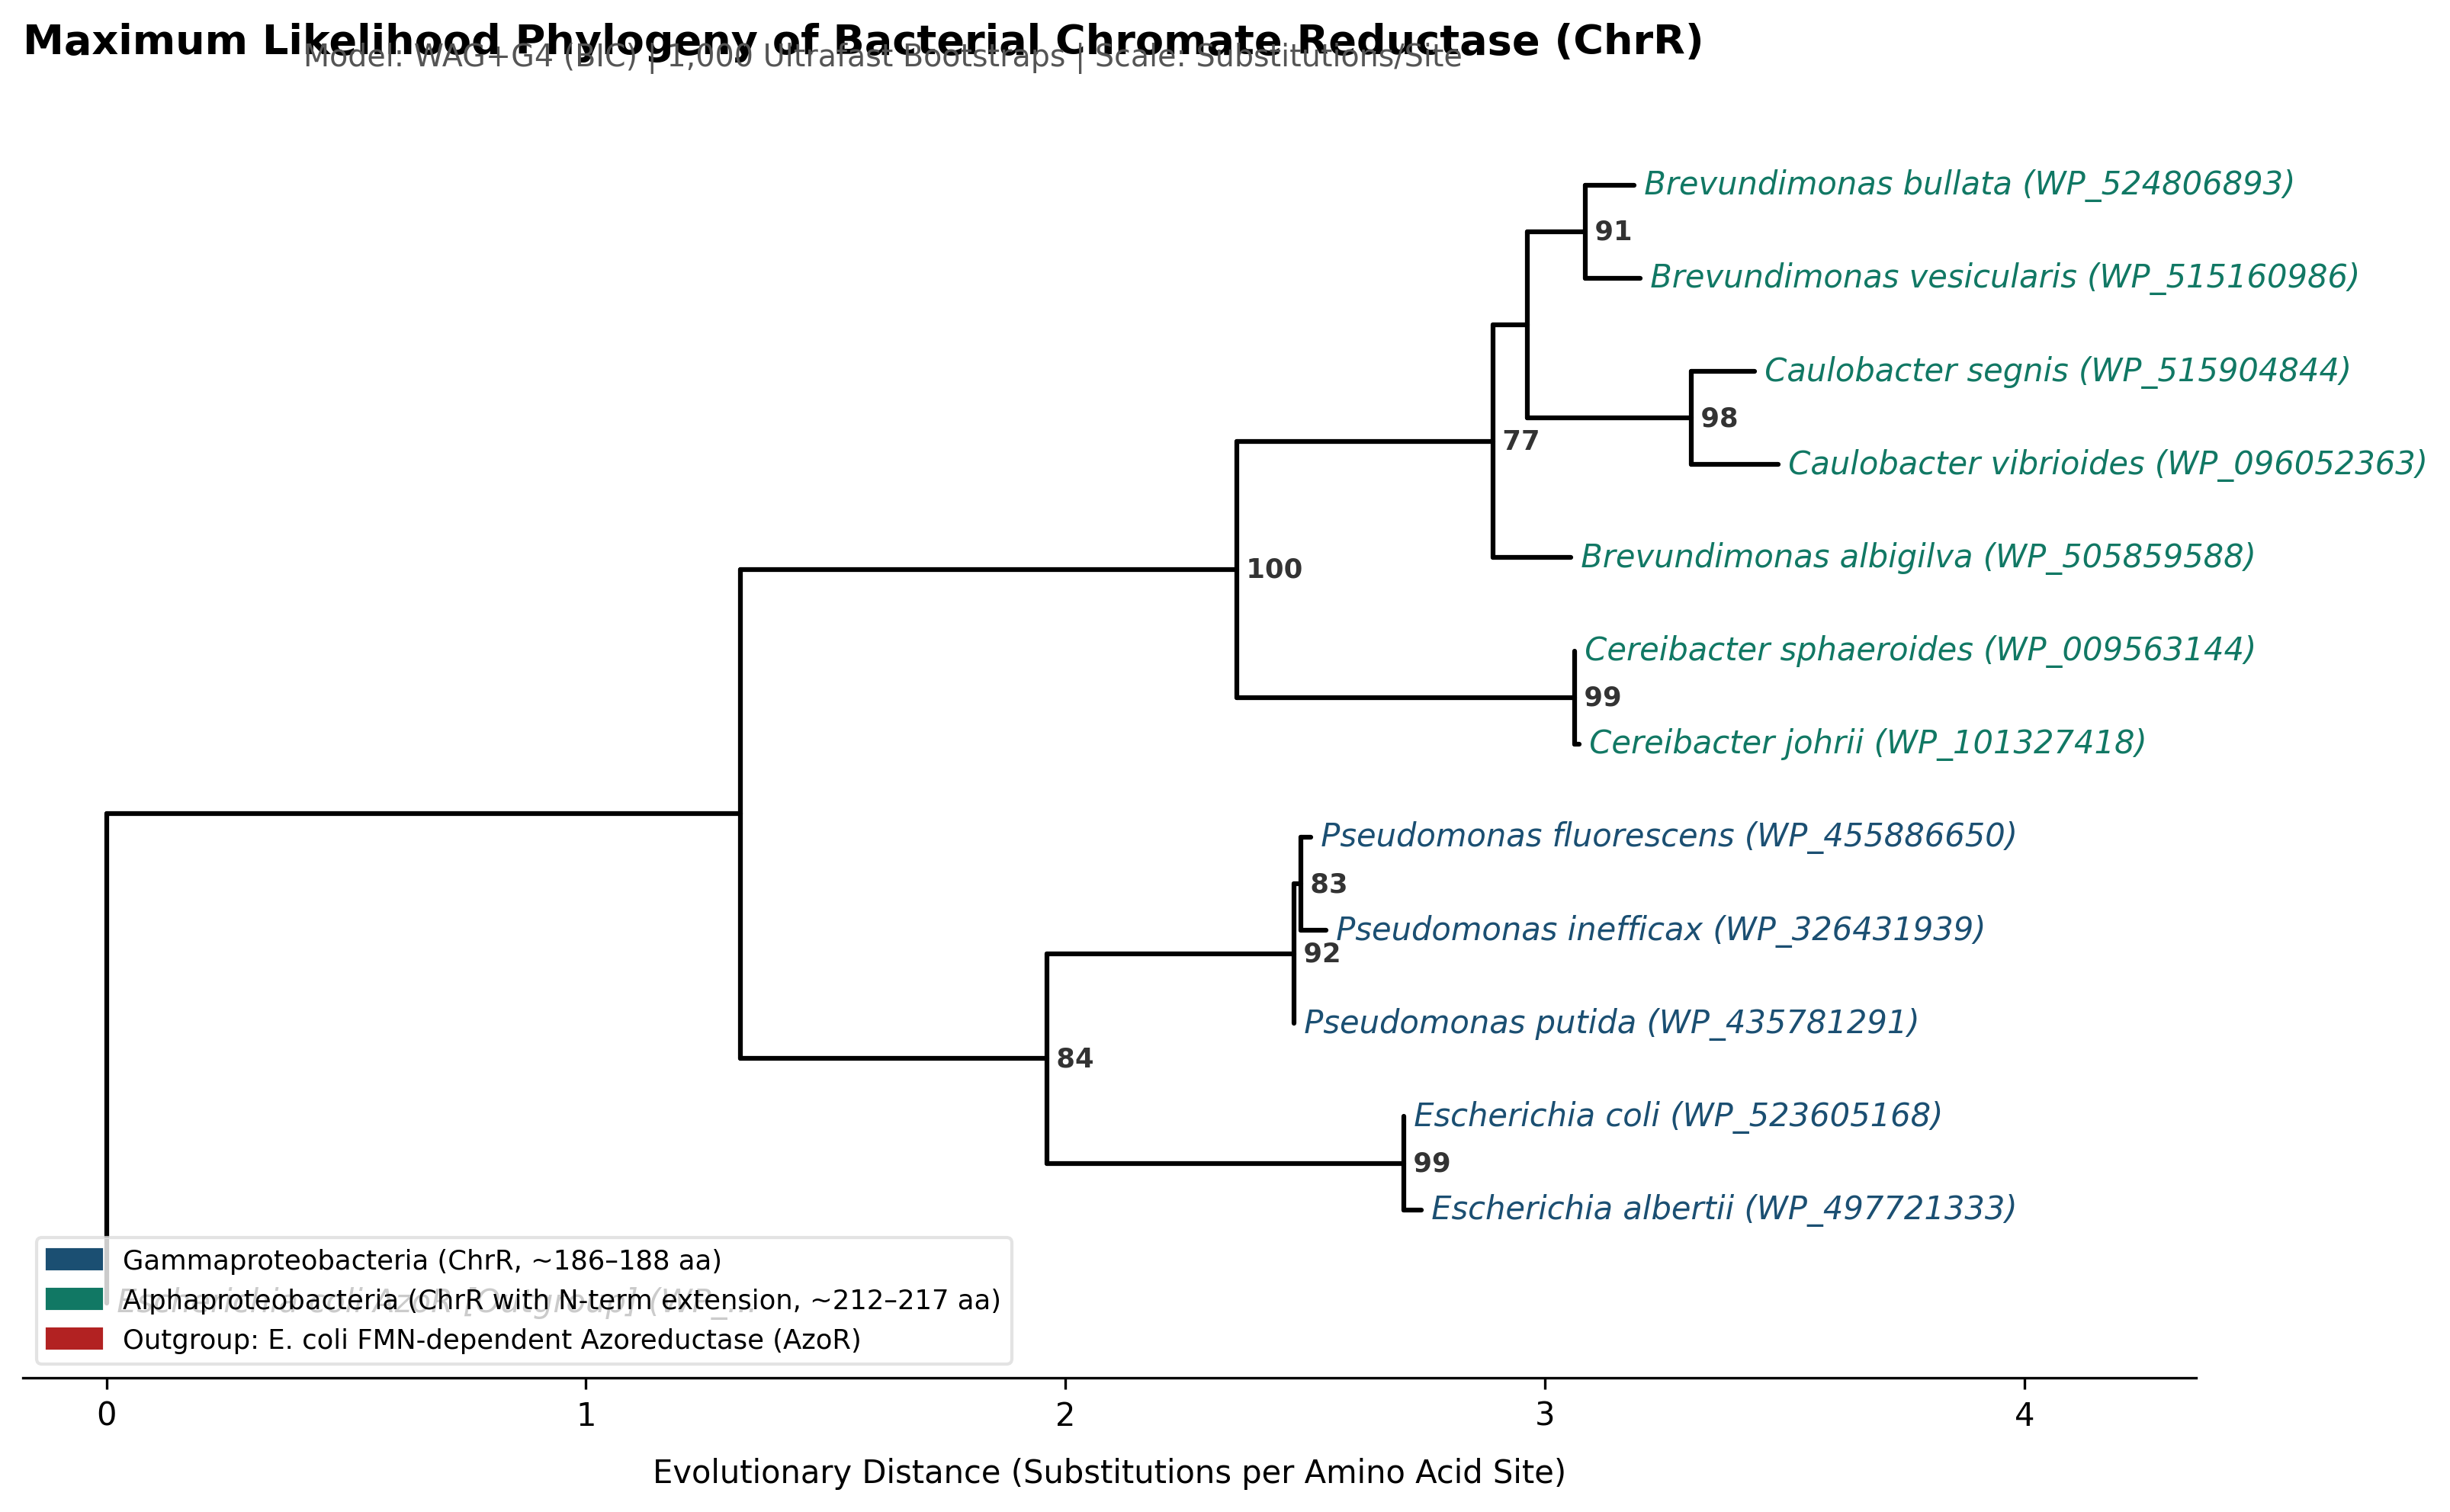

Saved high-resolution figures to Google Drive:
  - chrr_phylogeny_300dpi.png
  - chrr_phylogeny.pdf


In [8]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from Bio import Phylo

# 1. Load and ladderize the Maximum Likelihood tree from IQ-TREE
tree = Phylo.read("chrr_ml.treefile", "newick")
tree.root_with_outgroup({"name": "OUTGROUP_Ecoli_AzoR_WP_525205575"})
tree.ladderize(reverse=True)

# 2. Clean tip labels for publication display & assign taxonomic class colors
gamma_genera = ("Pseudomonas", "Escherichia")
alpha_genera = ("Brevundimonas", "Caulobacter", "Cereibacter")

label_colors = {}
for clade in tree.get_terminals():
    raw_name = clade.name
    if raw_name.startswith("OUTGROUP"):
        clean_name = "Escherichia coli AzoR [Outgroup] (WP_525205575)"
        color = "#B22222"  # Crimson for Outgroup
    else:
        parts = raw_name.split("_")
        species_str = f"{parts[0]} {parts[1]}"
        acc_str = f"({parts[2]}_{parts[3]})"
        clean_name = f"{species_str} {acc_str}"
        if parts[0] in gamma_genera:
            color = "#1B4F72"  # Deep Navy for Gammaproteobacteria
        elif parts[0] in alpha_genera:
            color = "#117864"  # Emerald Teal for Alphaproteobacteria
        else:
            color = "#2C3E50"
    clade.name = clean_name
    label_colors[clean_name] = color

# 3. Format internal node bootstrap values (show >= 50%)
for clade in tree.get_nonterminals():
    if clade.confidence is not None:
        if clade.confidence >= 50:
            clade.name = f"{int(round(clade.confidence))}"
        else:
            clade.name = ""

# 4. Plot high-resolution figure
fig, ax = plt.subplots(figsize=(11, 7), dpi=300)
Phylo.draw(
    tree,
    axes=ax,
    do_show=False,
    label_colors=label_colors,
    show_confidence=False
)

# Style typography and axes
for text in ax.texts:
    txt = text.get_text().strip()
    if txt.isdigit():  # Bootstrap support numbers
        text.set_fontsize(8.5)
        text.set_fontweight("bold")
        text.set_color("#333333")
    else:  # Species tip labels
        text.set_fontsize(10)
        text.set_fontstyle("italic")
        text.set_fontweight("medium")

ax.set_title(
    "Maximum Likelihood Phylogeny of Bacterial Chromate Reductase (ChrR)",
    fontsize=13, fontweight="bold", pad=18, loc="left"
)
plt.suptitle(
    "Model: WAG+G4 (BIC) | 1,000 Ultrafast Bootstraps | Scale: Substitutions/Site",
    fontsize=9.5, color="#555555", x=0.125, y=0.925, ha="left"
)

ax.set_xlabel("Evolutionary Distance (Substitutions per Amino Acid Site)", fontsize=10, labelpad=8)
ax.set_ylabel("")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.set_yticks([])

# Add taxonomic class legend
legend_handles = [
    mpatches.Patch(color="#1B4F72", label="Gammaproteobacteria (ChrR, ~186–188 aa)"),
    mpatches.Patch(color="#117864", label="Alphaproteobacteria (ChrR with N-term extension, ~212–217 aa)"),
    mpatches.Patch(color="#B22222", label="Outgroup: E. coli FMN-dependent Azoreductase (AzoR)")
]
ax.legend(handles=legend_handles, loc="lower left", frameon=True, facecolor="white", edgecolor="#DDDDDD", fontsize=8.5)

plt.tight_layout()
plt.savefig("chrr_phylogeny_300dpi.png", dpi=300, bbox_inches="tight")
plt.savefig("chrr_phylogeny.pdf", bbox_inches="tight")
plt.show()

print("Saved high-resolution figures to Google Drive:")
print("  - chrr_phylogeny_300dpi.png")
print("  - chrr_phylogeny.pdf")

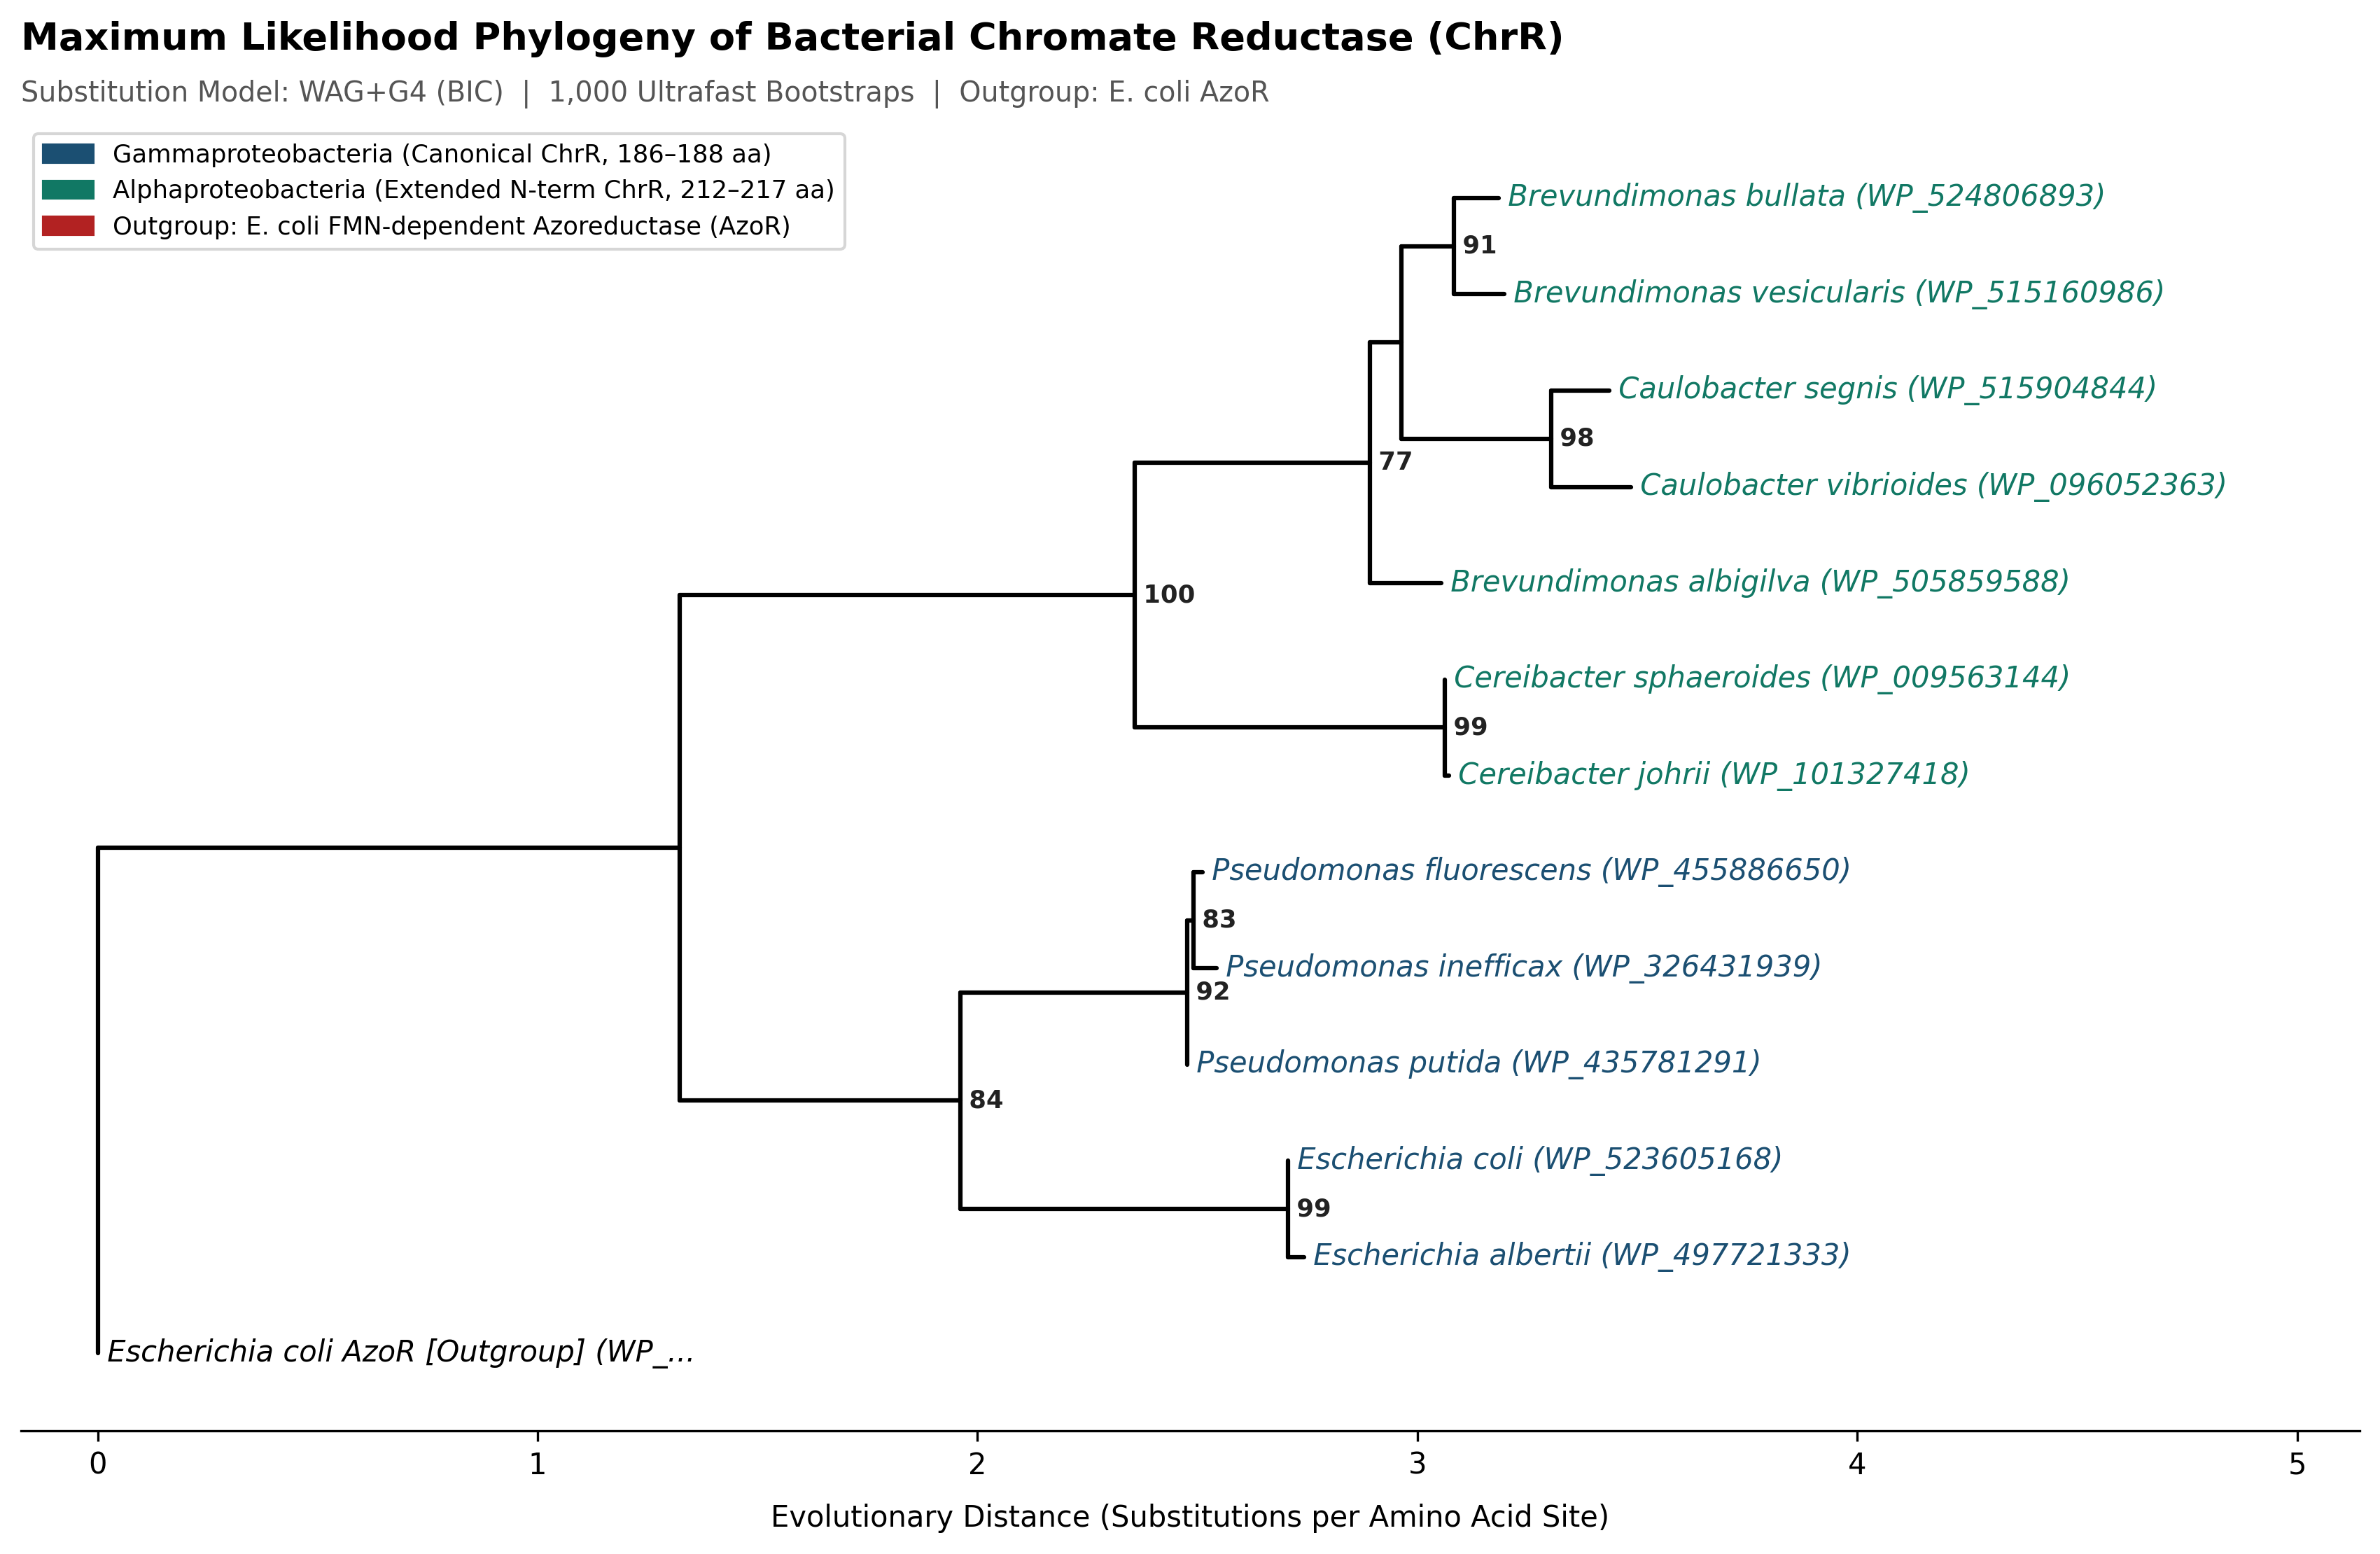

Polished figures updated in Google Drive!


In [9]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from Bio import Phylo

tree = Phylo.read("chrr_ml.treefile", "newick")
tree.root_with_outgroup({"name": "OUTGROUP_Ecoli_AzoR_WP_525205575"})
tree.ladderize(reverse=True)

gamma_genera = ("Pseudomonas", "Escherichia")
alpha_genera = ("Brevundimonas", "Caulobacter", "Cereibacter")

label_colors = {}
for clade in tree.get_terminals():
    raw_name = clade.name
    if raw_name.startswith("OUTGROUP"):
        clean_name = "Escherichia coli AzoR [Outgroup] (WP_525205575)"
        color = "#B22222"
    else:
        parts = raw_name.split("_")
        clean_name = f"{parts[0]} {parts[1]} ({parts[2]}_{parts[3]})"
        color = "#1B4F72" if parts[0] in gamma_genera else "#117864"
    clade.name = clean_name
    label_colors[clean_name] = color

for clade in tree.get_nonterminals():
    if clade.confidence is not None:
        clade.name = f"{int(round(clade.confidence))}" if clade.confidence >= 50 else ""

fig, ax = plt.subplots(figsize=(11.5, 7.5), dpi=300)
Phylo.draw(tree, axes=ax, do_show=False, label_colors=label_colors, show_confidence=False)

for text in ax.texts:
    txt = text.get_text().strip()
    if txt.isdigit():
        text.set_fontsize(8.5)
        text.set_fontweight("bold")
        text.set_color("#222222")
    else:
        text.set_fontsize(10)
        text.set_fontstyle("italic")

# Expand x-axis slightly so right-hand labels never clip
xmin, xmax = ax.get_xlim()
ax.set_xlim(xmin, xmax * 1.18)

# Clean, non-overlapping title & subtitle
ax.set_title(
    "Maximum Likelihood Phylogeny of Bacterial Chromate Reductase (ChrR)\n",
    fontsize=13, fontweight="bold", loc="left", pad=10
)
ax.text(
    0.0, 1.015,
    "Substitution Model: WAG+G4 (BIC)  |  1,000 Ultrafast Bootstraps  |  Outgroup: E. coli AzoR",
    transform=ax.transAxes, fontsize=9.5, color="#555555"
)

ax.set_xlabel("Evolutionary Distance (Substitutions per Amino Acid Site)", fontsize=10, labelpad=8)
ax.set_ylabel("")
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
ax.set_yticks([])

# Place legend in open upper-left canvas so the bottom outgroup label is 100% visible
legend_handles = [
    mpatches.Patch(color="#1B4F72", label="Gammaproteobacteria (Canonical ChrR, 186–188 aa)"),
    mpatches.Patch(color="#117864", label="Alphaproteobacteria (Extended N-term ChrR, 212–217 aa)"),
    mpatches.Patch(color="#B22222", label="Outgroup: E. coli FMN-dependent Azoreductase (AzoR)")
]
ax.legend(handles=legend_handles, loc="upper left", frameon=True, facecolor="white", edgecolor="#CCCCCC", fontsize=8.5)

plt.tight_layout()
plt.savefig("chrr_phylogeny_300dpi.png", dpi=300, bbox_inches="tight")
plt.savefig("chrr_phylogeny.pdf", bbox_inches="tight")
plt.show()
print("Polished figures updated in Google Drive!")

In [10]:
readme_text = """# Evolutionary Phylogeny of Bacterial Chromate Reductase (ChrR)

## Overview
An automated, reproducible computational phylogenetics pipeline investigating the evolutionary divergence and structural conservation of bacterial **Chromate Reductase (ChrR)**—a key flavin mononucleotide (FMN)-dependent oxidoreductase responsible for enzymatic reduction of toxic hexavalent chromium ($Cr^{6+}$) to insoluble trivalent chromium ($Cr^{3+}$).

## Pipeline & Methods
1. **Automated Sequence Curation (`Biopython / NCBI Entrez`):** Retrieved taxon-balanced RefSeq protein sequences (`186–217 aa`) across representative **Gammaproteobacteria** (*Pseudomonas*, *Escherichia*) and **Alphaproteobacteria** (*Brevundimonas*, *Caulobacter*, *Cereibacter*), rooted with *E. coli* FMN-dependent NADH-azoreductase (`AzoR`, `WP_525205575`) as a homologous flavodoxin-like outgroup.
2. **Multiple Sequence Alignment (`MAFFT v7.505`):** Performed iterative L-INS-i alignment (`--auto`) to map conserved catalytic residues and class-specific domain architecture.
3. **Maximum Likelihood Inference (`IQ-TREE 2`):** Evaluated empirical amino acid substitution models via ModelFinder Plus (`-m MFP`, selecting **`WAG+G4`** by BIC) and computed branch confidence with **1,000 ultrafast bootstrap replicates** (`-B 1000`).
4. **Hybrid Visualization (`Matplotlib` & `MEGA 12`):** Exported Newick trees (`chrr_ml.treefile`) for cross-verification in MEGA 12 Tree Explorer and generated 300-DPI publication figures.

## Key Biological Findings
* **Deep Class-Level Divergence (100% Bootstrap Support):** *ChrR* sequences segregate cleanly into two major evolutionary clades separating Gammaproteobacteria (`186–188 aa`) from Alphaproteobacteria (`212–217 aa`).
* **Lineage-Specific N-Terminal Domain Extension:** All examined Alphaproteobacterial *ChrR* homologs possess a conserved ~25-amino-acid N-terminal extension absent in canonical Gammaproteobacterial enzymes.
* **Conserved Catalytic Core:** Strict preservation of the FMN-binding signature (`G-S-L-R-K`) and key structural Proline/Glycine turn residues across both classes confirms strong purifying selection on cofactor-mediated electron transfer.

## Repository Contents
* `01_ChrR_Phylogeny.ipynb` — Complete Google Colab Python workflow
* `chrr_curated.fasta` — Curated RefSeq protein sequences
* `chrr_aligned.fasta` — MAFFT multiple sequence alignment
* `chrr_ml.treefile` — Maximum Likelihood Newick tree with bootstrap values
* `chrr_phylogeny_300dpi.png` — High-resolution annotated phylogenetic tree
"""

with open("README.md", "w") as f:
    f.write(readme_text)

print("Project 1 complete! README.md saved to your Google Drive folder.")

Project 1 complete! README.md saved to your Google Drive folder.
